# Model Inference : final evaluation of the best model (batchnorm+dropout) on the test set

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

import wandb

In [25]:
wandb.login()

device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

In [26]:
PET = Path.cwd().parent / "data" / "oxford-iiit-pet"

test_df = pd.read_csv(PET / "annotations" / "test.txt", sep=" ", header=None, usecols=[0, 2], names=["image", "species"])

test_df["label"] = test_df["species"] - 1  # 0 = cat, 1 = dog
test_df["breed"] = test_df["image"].str.rsplit("_", n=1).str[0]
test_df["path"] = test_df["image"].apply(lambda name: PET / "images" / f"{name}.jpg")

print(test_df.shape)
test_df.head()

(3669, 5)


,image,species,label,breed,path
0,Abyssinian_201,1,0,Abyssinian,/Users/nestordzadzamia/Projects/upgaming/data/...
1,Abyssinian_202,1,0,Abyssinian,/Users/nestordzadzamia/Projects/upgaming/data/...
2,Abyssinian_204,1,0,Abyssinian,/Users/nestordzadzamia/Projects/upgaming/data/...
3,Abyssinian_205,1,0,Abyssinian,/Users/nestordzadzamia/Projects/upgaming/data/...
4,Abyssinian_206,1,0,Abyssinian,/Users/nestordzadzamia/Projects/upgaming/data/...


In [27]:
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
])

In [28]:
class PetDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image = Image.open(row["path"]).convert("RGB")
        image = self.transform(image)

        label = int(row["label"])
        label = torch.tensor(label, dtype=torch.long)

        return image, label

In [29]:
test_dataset = PetDataset(test_df, transform=transform)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

In [30]:
class BatchNormDropoutCNN(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256*8*8, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [31]:
api = wandb.Api()
artifact = api.artifact("nestor_dzadzamia-free-university-of-tbilisi-/pet-classifier-cnn/batchnorm_dropout_cnn:latest")
model_dir = artifact.download()

model = BatchNormDropoutCNN().to(device)
model.load_state_dict(torch.load(f"{model_dir}/batchnorm_dropout_cnn.pt", map_location=device))
model.eval()

wandb:   1 of 1 files downloaded.  


BatchNormDropoutCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=

In [32]:
all_preds = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        preds = outputs.argmax(dim=1)
        all_preds.extend(preds.cpu().tolist())

test_df["pred"] = all_preds

In [33]:
print("Test accuracy:", accuracy_score(test_df["label"], test_df["pred"]))
print("Test F1 (macro):", f1_score(test_df["label"], test_df["pred"], average="macro"))
print(classification_report(test_df["label"], test_df["pred"], target_names=["cat", "dog"]))

Test accuracy: 0.7972199509403107
Test F1 (macro): 0.7614350935824203
              precision    recall  f1-score   support

         cat       0.71      0.64      0.67      1183
         dog       0.83      0.87      0.85      2486

    accuracy                           0.80      3669
   macro avg       0.77      0.75      0.76      3669
weighted avg       0.79      0.80      0.79      3669



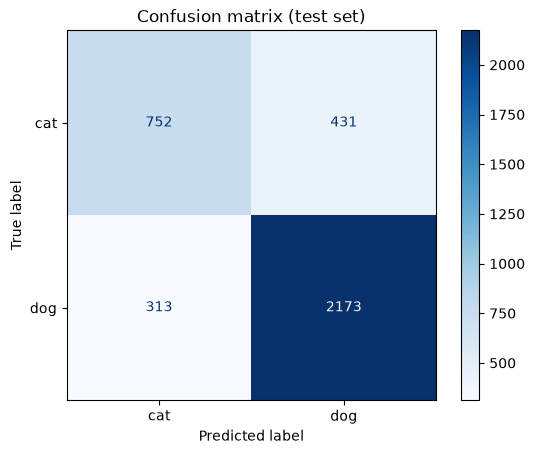

In [34]:
cm = confusion_matrix(test_df["label"], test_df["pred"])
ConfusionMatrixDisplay(cm, display_labels=["cat", "dog"]).plot(cmap="Blues")
plt.title("Confusion matrix (test set)")
plt.show()

breed
Bombay               0.556818
Bengal               0.570000
Birman               0.570000
Abyssinian           0.591837
Russian_Blue         0.610000
Sphynx               0.620000
British_Shorthair    0.630000
Ragdoll              0.630000
Siamese              0.640000
Persian              0.680000
Name: correct, dtype: float64


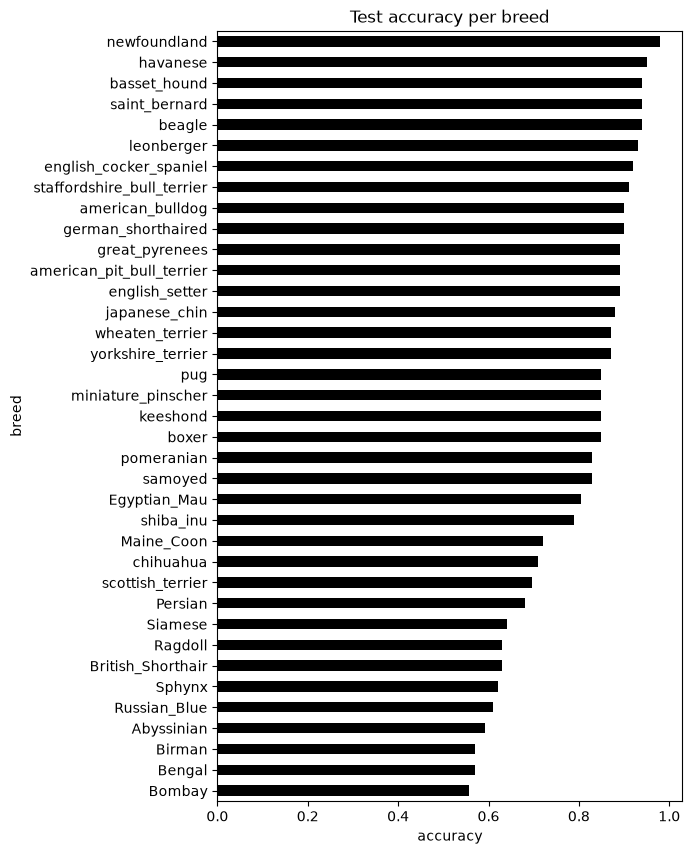

In [35]:
test_df["correct"] = test_df["label"] == test_df["pred"]

breed_acc = test_df.groupby("breed")["correct"].mean().sort_values()
print(breed_acc.head(10))

breed_acc.plot.barh(figsize=(6, 10), color="black", title="Test accuracy per breed")
plt.xlabel("accuracy")
plt.show()

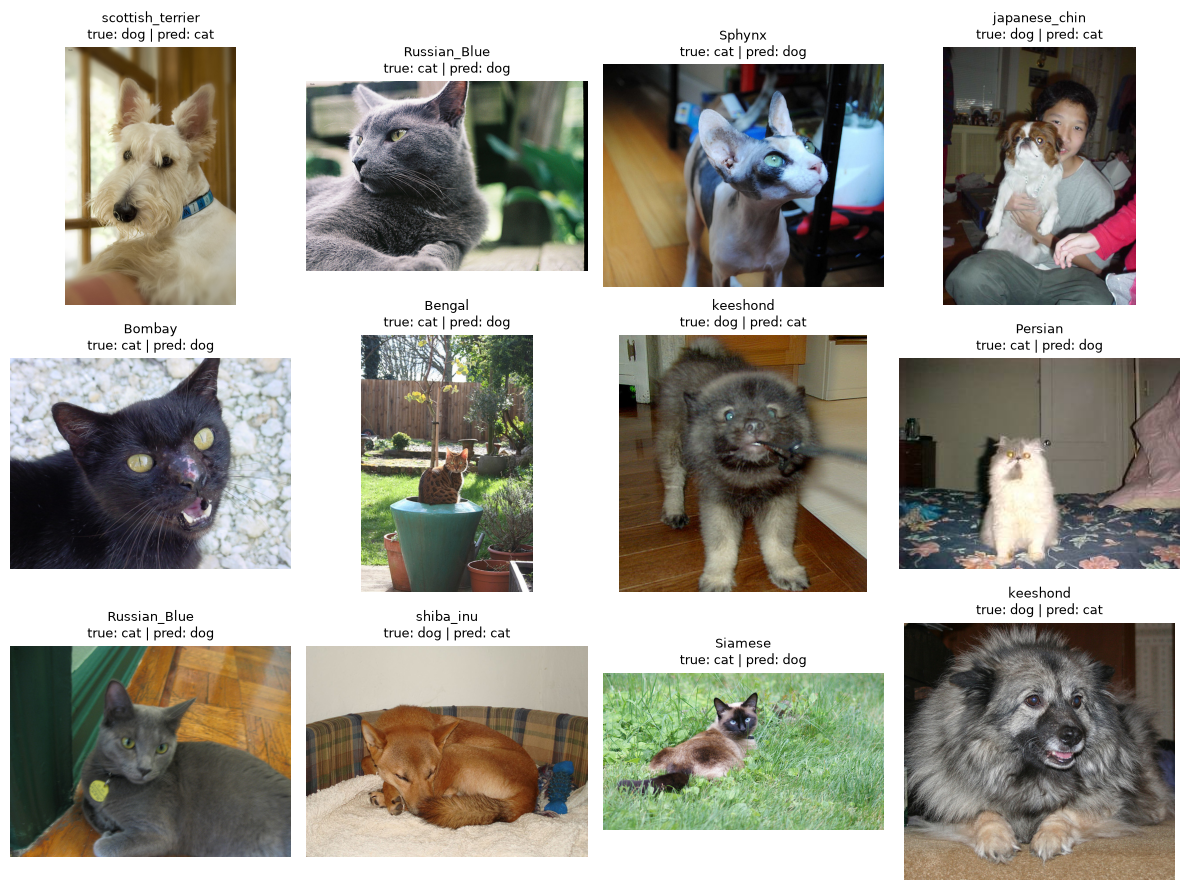

In [36]:
classes = ["cat", "dog"]
wrong = test_df[~test_df["correct"]].sample(12, random_state=42)

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for ax, (_, row) in zip(axes.flat, wrong.iterrows()):
    ax.imshow(Image.open(row["path"]).convert("RGB"))
    ax.set_title(f"{row['breed']}\ntrue: {classes[row['label']]} | pred: {classes[row['pred']]}", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()